# Deep Learning – Rendu 1 : CNN sur EuroSAT

**Auteur :** *BESSADET Theo* — **UE :** Deep Learning — **Deadline envisagée :** 13 décembre
**Données :** EuroSAT (torchvision) — occupation des sols en imagerie satellite, 10 classes, images 64×64×3.

## Consignes

- **Baseline** : un CNN dont l'architecture est 100 % maîtrisée (comme dans les premiers TP).
- **Réseaux pré-entraînés** : au moins un modèle classique (type ImageNet), idéalement deux pour comparer. Le transfert doit être fait par moi-même.
- **Stratégies d'apprentissage** : comparer au moins deux techniques, modèle complètement gelé vs fine-tuning (total ou partiel).
- **Taille de l'échantillon d'apprentissage** *(optionnel)* : comparer les performances selon la taille du jeu d'entraînement, jusqu'à 1 % des données.
- **Probing / sondage** : ajouter des hooks et brancher des sondes pour savoir où est encodée quelle information.
- **Analyses** : des zones de texte pour commenter les résultats.
- **Interprétabilité** : montrer quelque chose sur la décision, avec de la saillance ou du CAM.
- **Option** : comparer avec des modèles pré-entraînés sur les données cibles (HuggingFace).
- **Évaluation** : notebook + discussion rapide en séance de TP.

## Plan

1. **Données et préparation** : chargement d'EuroSAT, split train/val/test, normalisation, visualisation de quelques exemples.
2. **CNN fait maison (baseline)** : architecture codée par mes soins, entraînement, courbes, résultats.
3. **CNN construit avec les modules PyTorch** : *(à préciser : même architecture réécrite avec `nn.Module` / `nn.Sequential`, ou autre)*, entraînement et comparaison avec la baseline.
4. **Fine-tuning d'un modèle CNN pré-entraîné** : *(modèle à préciser)*
   - modèle gelé (extraction de caractéristiques) ;
   - fine-tuning partiel ;
   - fine-tuning complet.
5. **L-TAE** (article vu récemment) : *(à préciser : adaptation, entrée utilisée, comparaison)*
6. **Comparaison selon la taille du jeu d'entraînement** *(optionnel)* : 1 %, 10 %, 100 %.
7. **Probing** : hooks sur les couches intermédiaires et sondes.
8. **Interprétabilité** : saillance ou Grad-CAM.
9. **Conclusion** : tableau récapitulatif et discussion.


## 1. Données et préparation

- **Chargement** : `torchvision.datasets.EuroSAT` (27 000 images RGB 64×64, 10 classes), téléchargé dans `data/`. Les images sont converties en tenseurs `(N, 3, 64, 64)` dans [0, 1] puis toutes chargées sur le GPU (≈ 1,3 Go en float32) pour éviter les allers-retours CPU/GPU.
- **Split stratifié** (classes légèrement déséquilibrées, 2 000 à 3 000 images par classe) : 20 % test, puis 10 % du reste en validation → ≈ 19 400 / 2 200 / 5 400 images. Le **test est mis de côté** jusqu'à l'évaluation finale ; la validation sert à l'early stopping.
- **Normalisation par canal** : moyenne et écart-type calculés **sur le train uniquement** (pas de fuite vers val/test), puis appliqués aux trois jeux.

In [13]:
%load_ext autoreload
%autoreload 2

import copy
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from CNN import Conv, Dense, DropOut, Flatten, Modele, Pool, ReLu
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import inspect
from pathlib import Path
import mlflow

mlflow.set_tracking_uri("sqlite:///" + Path("mlflow.db").resolve().as_posix())
mlflow.set_experiment("EuroSAT_CNN")
print("device :", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device : cuda | NVIDIA GeForce RTX 5070 Ti


In [2]:
# Chargement : images PIL -> tenseurs (3, 64, 64) dans [0, 1]
eurosat = datasets.EuroSAT(root="data", download=True, transform=transforms.PILToTensor())   # uint8, (3, 64, 64)
classes = eurosat.classes

y = torch.tensor(eurosat.targets, dtype=torch.long)

loader = DataLoader(eurosat, batch_size=512, shuffle=False, num_workers=max(1, os.cpu_count() // 2))  # shuffle=False : ordre = celui de y
X = torch.cat([xb for xb, _ in tqdm(loader, desc="Chargement")])    # (27000, 3, 64, 64) uint8

# Split stratifié sur les indices : test 20 %, puis validation 10 % du reste
idx = np.arange(len(y))
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42, stratify=y.numpy())
idx_train, idx_val = train_test_split(idx_train, test_size=0.1, random_state=42, stratify=y[idx_train].numpy())

# Tout sur le device : uint8 -> float32 dans [0, 1], puis normalisation par canal (stats du train uniquement)
X = X.to(device).float().div_(255.)
y = y.to(device)
idx_train, idx_val, idx_test = (torch.tensor(i, device=device) for i in (idx_train, idx_val, idx_test))

mean = X[idx_train].mean(dim=(0, 2, 3), keepdim=True)   # (1, 3, 1, 1)
std = X[idx_train].std(dim=(0, 2, 3), keepdim=True)
X.sub_(mean).div_(std)                                  # en place : évite une copie de 1,3 Go

X_train, y_train = X[idx_train], y[idx_train]
X_val,   y_val   = X[idx_val],   y[idx_val]
X_test,  y_test  = X[idx_test],  y[idx_test]
del X

print("X_train :", X_train.shape, "\nX_val :", X_val.shape, "\nX_test :", X_test.shape)
print("Classes :", classes)

Chargement:   0%|          | 0/53 [00:18<?, ?it/s]

X_train : torch.Size([19440, 3, 64, 64]) 
X_val : torch.Size([2160, 3, 64, 64]) 
X_test : torch.Size([5400, 3, 64, 64])
Classes : ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


torch.Size([3, 64, 64]) torch.Size([1, 1, 1, 3, 64, 64])


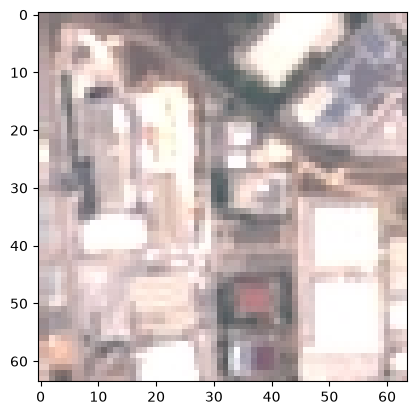

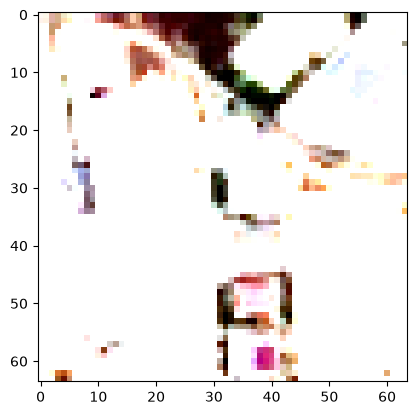

In [3]:
X1 = X_train[0,:,:,:]
X1_brute = X1 * std[:, None, None] + mean[:, None, None]

print(X1.shape, X1_brute.shape)

plt.imshow(X1_brute.cpu().squeeze(0,1,2).permute(1, 2, 0))
plt.figure()
plt.imshow(X1.cpu().permute(1, 2, 0).clamp(0, 1))

## 2. CNN fait maison (baseline)

Les couches et la classe `Modele` sont importées depuis `CNN.py` (repris de `CNN.ipynb`).

**Architecture** (inspirée du modèle "large" de MNIST, adaptée à des images 64×64×3) : 3 blocs `Conv 3×3 (same) → ReLu → MaxPool 2×2`, avec un nombre de filtres doublé à chaque pooling (32 → 64 → 128), puis `DropOut(0.3) → Flatten → Dense(128) → ReLu → Dense(10)`.

| Étape | Sortie |
|---|---|
| Entrée | 3 × 64 × 64 |
| Bloc 1 (32 filtres) | 32 × 32 × 32 |
| Bloc 2 (64 filtres) | 64 × 16 × 16 |
| Bloc 3 (128 filtres) | 128 × 8 × 8 |
| Flatten → Dense → Dense | 8 192 → 128 → 10 |

- **Padding `same`** : la taille n'est réduite que par le pooling, ce qui garde une carte 8×8 en sortie des features (utile plus tard pour le Grad-CAM).
- **3 blocs** plutôt que 2 : les images sont plus grandes et plus riches (textures, couleurs) que MNIST.
- **≈ 1,14 M paramètres**, dont ≈ 92 % dans la première Dense : c'est la principale source de sur-apprentissage, d'où le DropOut juste avant.

**Hyperparamètres** : SGD simple (pas de momentum, comme dans `Modele`), `lr = 0.05` (plus faible que sur MNIST car le réseau est plus profond et sans BatchNorm), `batch_size = 128`, 60 epochs maximum, early stopping sur la loss de validation avec `patience = 8`. Ces valeurs sont un point de départ, à ajuster sur la validation (jamais sur le test).

In [19]:
def probas(model, x):
    model.eval()
    with torch.no_grad():
        logits = torch.cat([model.forward(x[i:i + model.batch_size]) for i in range(0, len(x), model.batch_size)])
    return torch.softmax(logits.double(), dim=1).cpu().numpy()   # double : sklearn vérifie que chaque ligne somme à 1

def probas_torch(model, x, batch_size=128):
    model.eval()
    with torch.no_grad():
        logits = torch.cat([model(x[i:i + batch_size]) for i in range(0, len(x), batch_size)])
    return torch.softmax(logits.double(), dim=1).cpu().numpy()

def stats_par_classe(proba, y_true):
    '''DataFrame : une ligne par classe + une ligne "moyenne" ; colonnes : loss, accuracy, F1, ROC AUC, average precision'''
    pred = proba.argmax(axis=1)
    y_bin = np.eye(len(classes))[y_true]          # (N, n_classes) : one-hot, pour les métriques "une classe contre les autres"
    lignes = []
    for k in range(len(classes)):
        masque = y_true == k
        lignes.append({
            "loss":              -np.log(np.clip(proba[masque, k], 1e-12, None)).mean(),   # -log(proba de la vraie classe), images de la classe k
            "accuracy":          (pred[masque] == k).mean(),                               # = rappel de la classe k
            "F1":                f1_score(y_bin[:, k], pred == k),
            "ROC AUC":           roc_auc_score(y_bin[:, k], proba[:, k]),
            "average precision": average_precision_score(y_bin[:, k], proba[:, k]),
        })
    df = pd.DataFrame(lignes, index=classes)
    df.loc["moyenne (macro)"] = df.mean()
    return df

def log_confusion_probas(proba, y_true):
    '''Dans le run MLflow actif : matrice de confusion (image) et stats par classe (table) en artefacts'''
    pred = proba.argmax(axis=1)
    fig, ax = plt.subplots(figsize=(8, 8))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title("Matrice de confusion (validation)")
    fig.tight_layout()
    mlflow.log_figure(fig, "matrice_confusion_val.png")
    plt.close(fig)       # évite l'affichage de la figure dans la cellule
    df = stats_par_classe(proba, y_true).round(4).rename_axis("classe").reset_index()
    mlflow.log_table(df, "stats_par_classe_val.json")


In [20]:
def creer_modele_v2(input_shape=(3, 64, 64), EPOCH=60, lr=0.1, batch_size=128, patience=10, eps=1e-4, **kwargs):
    mp, r = Pool(2, 2, 'max'), ReLu()     # sans état : réutilisables
    features = [Conv(3, 32, 3, padding='same'), r, mp,                                          # (B, 32, 32, 32)
                Conv(32, 64, 3, padding='same'), r, Conv(64, 64, 3, padding='same'), r, mp,     # (B, 64, 16, 16)
                Conv(64, 128, 3, padding='same'), r, Conv(128, 128, 3, padding='same'), r, mp,  # (B, 128, 8, 8)
                Conv(128, 256, 3, padding='same'), r, mp,                                       # (B, 256, 4, 4)
                DropOut(p=0.3)]
    classifier = [Flatten(), Dense(n_out=128), r, DropOut(p=0.3), Dense(n_out=10)]              # 4096 -> 128 -> 10
    return Modele(features, classifier, input_shape=input_shape, EPOCH=EPOCH, lr=lr, batch_size=batch_size, patience=patience, eps=eps, **kwargs)

configs = {
    "base":             dict(),
    "augmentation":     dict(augment=True),
    "momentum + decay": dict(lr=0.02, momentum=0.9, lr_decay=0.95),
    "tout":             dict(lr=0.02, momentum=0.9, lr_decay=0.95, augment=True),
}

modeles_v2, temps_v2 = {}, {}
defauts = {k: v.default for k, v in inspect.signature(creer_modele_v2).parameters.items()
           if v.default is not inspect.Parameter.empty}
for nom, params in configs.items():
    print(f"=== {nom} ===")
    torch.manual_seed(42)
    modeles_v2[nom] = creer_modele_v2(**params)
    with mlflow.start_run(run_name=f"maison {nom}"):
        mlflow.log_params({**defauts, **params, "modele": nom, "implementation": "maison", "seed": 42})
        mlflow.log_text(_ih[-1], "cellule_modeles_v2.py")
        t0 = time.time()
        modeles_v2[nom].fit(X_train, y_train, X_val, y_val)
        temps_v2[nom] = time.time() - t0
        for epoch, (tl, ta, vl, va) in enumerate(modeles_v2[nom].perf_fit):
            mlflow.log_metrics({"train_loss": float(tl), "train_acc": float(ta),
                                "val_loss": float(vl), "val_acc": float(va)}, step=epoch)
        mlflow.log_metric("temps_min", temps_v2[nom] / 60)
        log_confusion_probas(probas(modeles_v2[nom], X_val), y_val.cpu().numpy())

for nom, m in modeles_v2.items():
    loss, acc = m.evaluate(X_val, y_val)
    f1 = f1_score(y_val.cpu().numpy(), m.predict(X_val).cpu().numpy(), average="macro")
    print(f"{nom:<18} val_loss={loss:.4f}  acc={acc * 100:.2f} %  F1={f1:.4f}  epochs={len(m.perf_fit)}  {temps_v2[nom] / 60:.1f} min")

=== base ===


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

... (195 outputs left out)

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Stop apres 60 epochs : val_loss=0.0992
base               val_loss=0.2025  acc=94.49 %  F1=0.9438  epochs=47  2.1 min
augmentation       val_loss=0.1219  acc=96.06 %  F1=0.9599  epochs=51  2.4 min
momentum + decay   val_loss=0.1627  acc=95.23 %  F1=0.9515  epochs=38  1.7 min
tout               val_loss=0.0992  acc=97.13 %  F1=0.9705  epochs=60  2.8 min


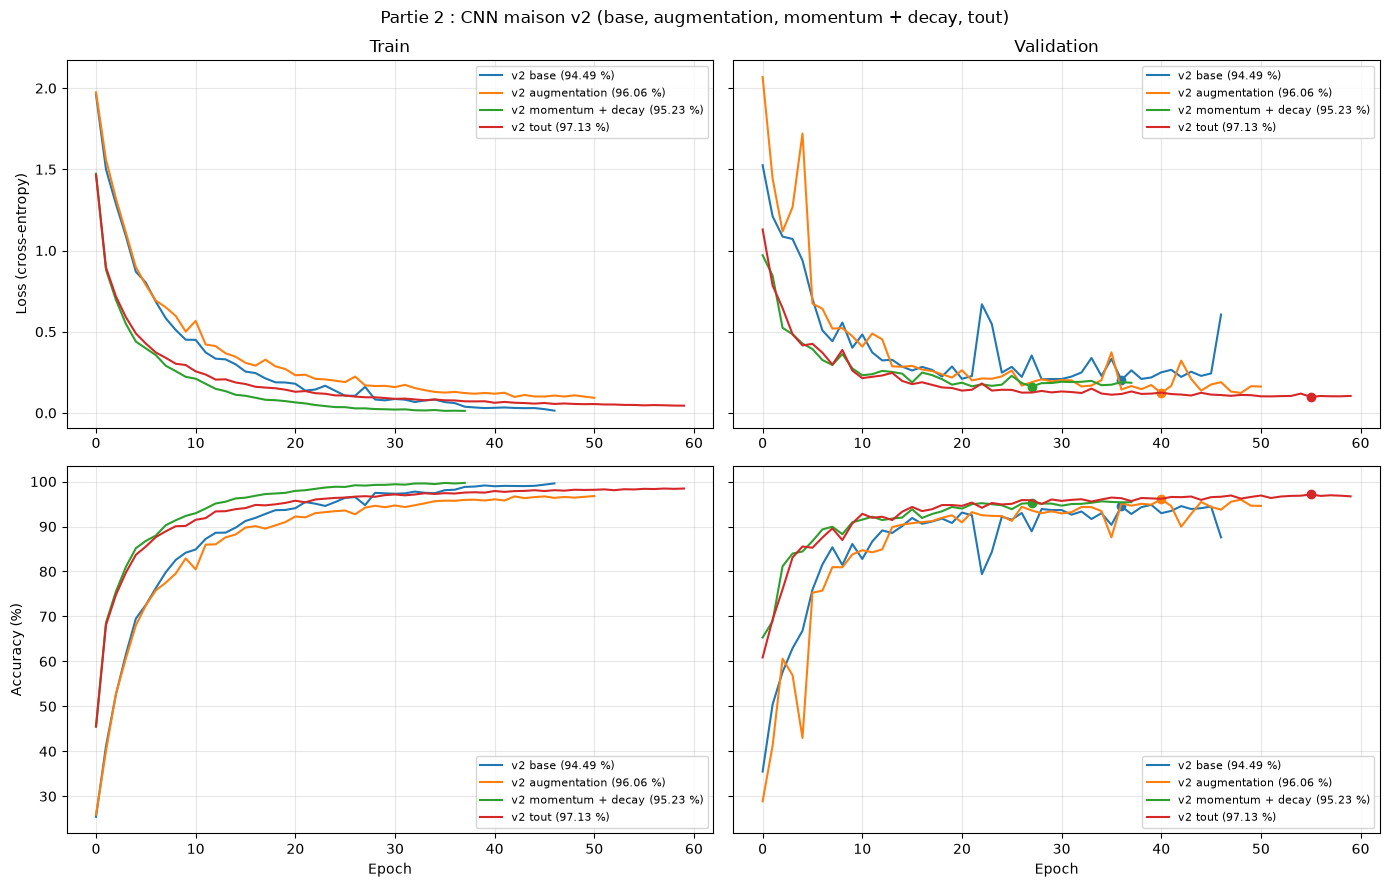

In [21]:
# Vue d'ensemble de la partie 2 : lignes = loss / accuracy, colonnes = train / validation
# Point = meilleure epoch (poids conservés par l'early stopping) ; la légende donne l'accuracy de validation à cette epoch
runs = {**{f"v2 {nom}": m.perf_fit for nom, m in modeles_v2.items() if getattr(m, "perf_fit", None)}}

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey="row")
for i, (nom, perf_fit) in enumerate(runs.items()):
    perf = np.array(perf_fit)           # colonnes : train_loss, train_acc, val_loss, val_acc
    best = perf[:, 2].argmin()
    label = f"{nom} ({perf[best, 3] * 100:.2f} %)"
    for j, (col_loss, col_acc) in enumerate([(0, 1), (2, 3)]):     # j = 0 : train, j = 1 : validation
        axes[0, j].plot(perf[:, col_loss], color=f"C{i}", label=label)
        axes[1, j].plot(perf[:, col_acc] * 100, color=f"C{i}", label=label)
    axes[0, 1].plot(best, perf[best, 2], "o", color=f"C{i}")
    axes[1, 1].plot(best, perf[best, 3] * 100, "o", color=f"C{i}")

axes[0, 0].set_title("Train")
axes[0, 1].set_title("Validation")
axes[0, 0].set_ylabel("Loss (cross-entropy)")
axes[1, 0].set_ylabel("Accuracy (%)")
for ax in axes[1]:
    ax.set_xlabel("Epoch")
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Partie 2 : CNN maison v2 (base, augmentation, momentum + decay, tout)")
plt.tight_layout()
plt.savefig("data/resume_partie2_maison_portable.png", dpi=150, bbox_inches="tight")
plt.show()

loss              : 0.0992
accuracy          : 97.13 %
F1 macro          : 0.9705
ROC AUC (ovr)     : 0.9992
average precision : 0.9934

                      precision    recall  f1-score   support

          AnnualCrop      0.943     0.958     0.950       240
              Forest      1.000     0.992     0.996       240
HerbaceousVegetation      0.963     0.963     0.963       240
             Highway      0.980     0.995     0.988       200
          Industrial      0.975     0.980     0.978       200
             Pasture      0.945     0.969     0.957       160
       PermanentCrop      0.939     0.930     0.935       200
         Residential      0.987     0.983     0.985       240
               River      0.979     0.950     0.964       200
             SeaLake      0.992     0.988     0.990       240

            accuracy                          0.971      2160
           macro avg      0.970     0.971     0.970      2160
        weighted avg      0.971     0.971     0.971    

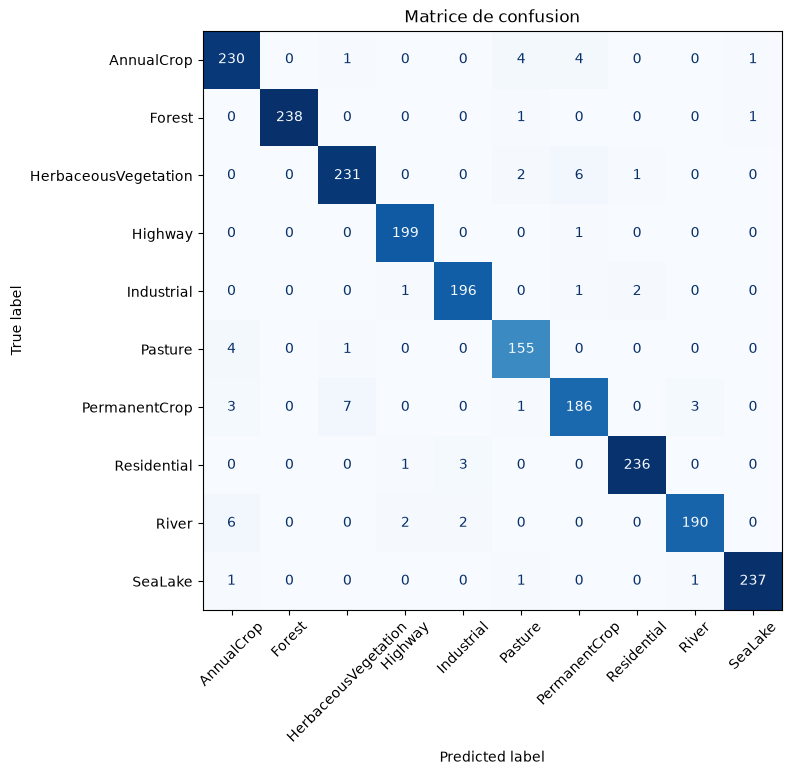

In [22]:
# Resumé stat du modele_v2 "tout" 
y_np = y_val.cpu().numpy()
proba = probas(modeles_v2["tout"], X_val)
pred = proba.argmax(axis=1)

loss, accuracy = modeles_v2["tout"].evaluate(X_val, y_val)
print(f"loss              : {loss:.4f}")
print(f"accuracy          : {accuracy * 100:.2f} %")
print(f"F1 macro          : {f1_score(y_np, pred, average='macro'):.4f}")
print(f"ROC AUC (ovr)     : {roc_auc_score(y_np, proba, multi_class='ovr'):.4f}")
print(f"average precision : {average_precision_score(np.eye(len(classes))[y_np], proba, average='macro'):.4f}")
print()
print(classification_report(y_np, pred, target_names=classes, digits=3))

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(y_np, pred), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Matrice de confusion")
plt.tight_layout()
plt.savefig("data/matrice_confusion_maison_v2.png", dpi=150, bbox_inches="tight")
plt.show() 

## 3. CNN construit avec les modules PyTorch

**Même architecture** que la baseline, réécrite avec `nn.Sequential` : `nn.Conv2d(padding='same')`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Dropout`, `nn.Flatten`, `nn.Linear`. La boucle d'entraînement utilise `torch.optim.SGD` et `nn.CrossEntropyLoss` (log-softmax + NLL, comme dans `Modele`).

**Mêmes hyperparamètres** (SGD sans momentum, `lr = 0.05`, `batch_size = 128`, 60 epochs max, `patience = 8` sur la loss de validation, restauration des meilleurs poids) pour que la comparaison porte sur l'implémentation et non sur les réglages.

Seule différence volontairement conservée : l'**initialisation par défaut de PyTorch** (Kaiming uniforme) au lieu de `randn / √(fan_in)`. On pourrait aussi passer à Adam ou ajouter du momentum, mais la comparaison ne serait plus équitable.

In [23]:
def creer_modele_torch_v2():
    r, mp = nn.ReLU(), nn.MaxPool2d(2, 2)
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding='same'), r, mp,                                                # (B, 32, 32, 32)
        nn.Conv2d(32, 64, 3, padding='same'), r, nn.Conv2d(64, 64, 3, padding='same'), r, mp,      # (B, 64, 16, 16)
        nn.Conv2d(64, 128, 3, padding='same'), r, nn.Conv2d(128, 128, 3, padding='same'), r, mp,   # (B, 128, 8, 8)
        nn.Conv2d(128, 256, 3, padding='same'), r, mp,                                             # (B, 256, 4, 4)
        nn.Dropout(0.3),
        nn.Flatten(), nn.Linear(256 * 4 * 4, 128), r, nn.Dropout(0.3), nn.Linear(128, 10),         # 4096 -> 128 -> 10
    ).to(device)

def augmenter_torch(x):
    '''Parmi les 8 symétries du carré (4 rotations de 90° x retournement), tirée au hasard pour chaque image. x : (N, C, H, W) avec H = W'''
    N = x.shape[0]
    k = torch.randint(0, 4, (N,), device=x.device)
    x = torch.stack([torch.rot90(x, j, dims=(2, 3)) for j in range(4)])    # (4, N, C, H, W)
    x = x[k, torch.arange(N, device=x.device)]                              # (N, C, H, W)
    flip = torch.rand(N, device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def evaluer_torch(model, x, y, batch_size=128):
    model.eval()
    critere = nn.CrossEntropyLoss(reduction='sum')
    total_loss, correct = 0., 0
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            yhat = model(x[i:i+batch_size])
            total_loss += critere(yhat, y[i:i+batch_size]).item()
            correct += (yhat.argmax(dim=1) == y[i:i+batch_size]).sum().item()
    return total_loss / len(x), correct / len(x)   # loss, accuracy

def predire_torch(model, x, batch_size=128):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i+batch_size]).argmax(dim=1) for i in range(0, len(x), batch_size)])

def fit_torch(model, x, y, x_val, y_val, EPOCH=60, lr=0.05, batch_size=128, patience=8, eps=1e-4,
              momentum=0.0, lr_decay=1.0, augment=False):
    optimiseur = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimiseur, gamma=lr_decay)   # lr de l'epoch e = lr * lr_decay**e
    critere = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=True, drop_last=True)
    perf_fit, min_loss, best_state, wait = [], float("inf"), None, 0

    barre_epoch = tqdm(range(EPOCH), desc="Epochs")
    for epoch in barre_epoch:
        model.train()
        batch_loss, batch_accuracy = [], []
        for xb, yb in tqdm(loader, desc="Batchs", leave=False):
            if augment:
                xb = augmenter_torch(xb)
            yhat = model(xb)
            loss = critere(yhat, yb)
            optimiseur.zero_grad()
            loss.backward()
            optimiseur.step()
            batch_loss.append(loss.item())
            batch_accuracy.append((yhat.argmax(dim=1) == yb).float().mean().item())
        scheduler.step()    # fin d'epoch : mise à jour du lr

        val_loss, val_accuracy = evaluer_torch(model, x_val, y_val, batch_size)

        perf_fit.append([np.mean(batch_loss), np.mean(batch_accuracy), val_loss, val_accuracy])
        if mlflow.active_run():
            mlflow.log_metrics({"train_loss": float(np.mean(batch_loss)), "train_acc": float(np.mean(batch_accuracy)),
                                "val_loss": float(val_loss), "val_acc": float(val_accuracy)}, step=epoch)

        barre_epoch.set_postfix(loss=f"{np.mean(batch_loss):.4f}", val_loss=f"{val_loss:.4f}", val_acc=f"{val_accuracy:.4f}")

        if val_loss < min_loss - eps:
            wait, min_loss = 0, val_loss
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                tqdm.write(f"Early stop at epoch {epoch + 1}")
                break

    model.load_state_dict(best_state)
    model.eval()
    print(f"Stop apres {len(perf_fit)} epochs : val_loss={min_loss:.4f}")
    return perf_fit

In [24]:
configs_torch = {
    "v2":      (creer_modele_torch_v2, dict(lr=0.1, patience=10)),
    "v2 tout": (creer_modele_torch_v2, dict(lr=0.02, patience=10, momentum=0.9, lr_decay=0.95, augment=True)),
}

modeles_t, perfs_t, temps_t = {}, {}, {}
defauts_torch = {k: v.default for k, v in inspect.signature(fit_torch).parameters.items()
                 if v.default is not inspect.Parameter.empty}
for nom, (creer, params) in configs_torch.items():
    print(f"=== {nom} ===")
    torch.manual_seed(42)
    modeles_t[nom] = creer()
    n_params = sum(p.numel() for p in modeles_t[nom].parameters())
    print(f"Paramètres : {n_params:,}")
    with mlflow.start_run(run_name=f"torch {nom}"):
        mlflow.log_params({**defauts_torch, **params, "modele": nom, "implementation": "pytorch", "seed": 42, "n_params": n_params})
        mlflow.log_text(_ih[-1], "cellule_modeles_torch.py")
        mlflow.log_text(inspect.getsource(creer), "architecture.py")
        t0 = time.time()
        perfs_t[nom] = fit_torch(modeles_t[nom], X_train, y_train, X_val, y_val, **params)
        temps_t[nom] = time.time() - t0
        val_loss, val_acc = evaluer_torch(modeles_t[nom], X_val, y_val)
        f1 = f1_score(y_val.cpu().numpy(), predire_torch(modeles_t[nom], X_val).cpu().numpy(), average="macro")
        mlflow.log_metrics({"best_val_loss": val_loss, "best_val_acc": val_acc, "val_f1_macro": f1,
                            "epochs": len(perfs_t[nom]), "temps_min": temps_t[nom] / 60})
        log_confusion_probas(probas_torch(modeles_t[nom], X_val), y_val.cpu().numpy())


=== v2 ===
Paramètres : 1,098,634


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

... (97 outputs left out)

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Stop apres 60 epochs : val_loss=0.1330


In [25]:
y_np = y_val.cpu().numpy()
for nom, m in modeles_t.items():
    loss, acc = evaluer_torch(m, X_val, y_val)
    f1 = f1_score(y_np, predire_torch(m, X_val).cpu().numpy(), average="macro")
    print(f"{nom:<10} val_loss={loss:.4f}  acc={acc * 100:.2f} %  F1={f1:.4f}  epochs={len(perfs_t[nom])}  {temps_t[nom] / 60:.1f} min")

v2         val_loss=0.2802  acc=92.31 %  F1=0.9210  epochs=42  0.9 min
v2 tout    val_loss=0.1330  acc=95.19 %  F1=0.9504  epochs=60  1.4 min


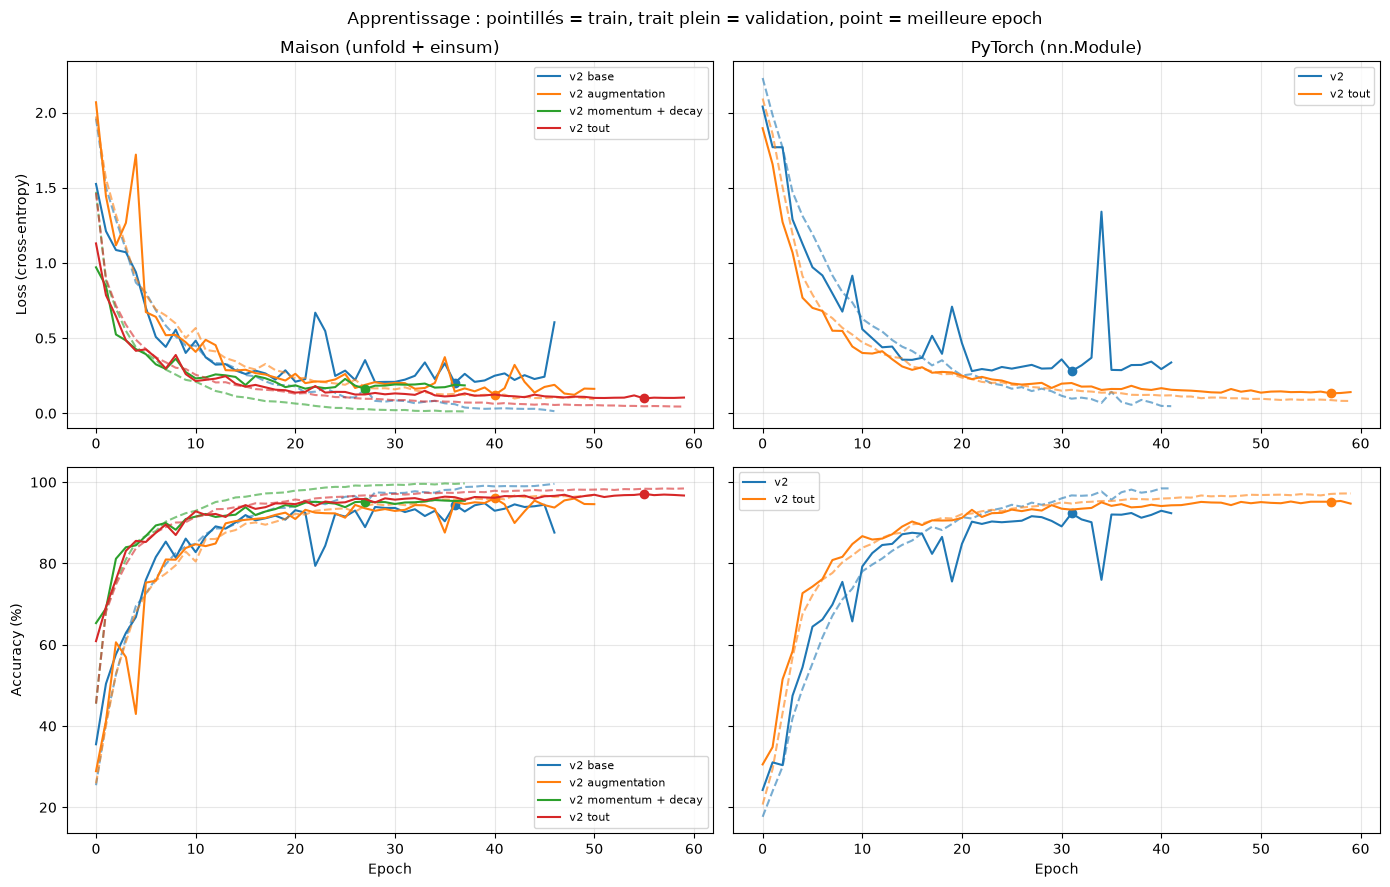

In [26]:
# Vue d'ensemble : lignes = loss / accuracy, colonnes = implémentation maison / PyTorch
# Pointillés = train, trait plein = validation, point = meilleure epoch (poids conservés par l'early stopping)
groupes = {
    "Maison (unfold + einsum)": {**{f"v2 {nom}": m.perf_fit for nom, m in modeles_v2.items() if getattr(m, "perf_fit", None)}},
    "PyTorch (nn.Module)":      perfs_t,
}

fig, axes = plt.subplots(2, len(groupes), figsize=(7 * len(groupes), 9), sharey="row", squeeze=False)
for j, (titre, runs) in enumerate(groupes.items()):
    for i, (nom, perf_fit) in enumerate(runs.items()):
        perf = np.array(perf_fit)           # colonnes : train_loss, train_acc, val_loss, val_acc
        best = perf[:, 2].argmin()
        couleur = f"C{i}"
        axes[0, j].plot(perf[:, 0], color=couleur, linestyle="--", alpha=0.6)
        axes[0, j].plot(perf[:, 2], color=couleur, label=nom)
        axes[0, j].plot(best, perf[best, 2], "o", color=couleur)
        axes[1, j].plot(perf[:, 1] * 100, color=couleur, linestyle="--", alpha=0.6)
        axes[1, j].plot(perf[:, 3] * 100, color=couleur, label=nom)
        axes[1, j].plot(best, perf[best, 3] * 100, "o", color=couleur)
    axes[0, j].set_title(titre)
    axes[1, j].set_xlabel("Epoch")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
axes[0, 0].set_ylabel("Loss (cross-entropy)")
axes[1, 0].set_ylabel("Accuracy (%)")
fig.suptitle("Apprentissage : pointillés = train, trait plein = validation, point = meilleure epoch")
plt.tight_layout()
plt.savefig("data/resume_partie3_maison_vs_pytorch.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Comparaison des deux implémentations

Les deux modèles étant **figés** (aucun choix ne sera fait à partir de ces chiffres), on peut les évaluer sur le **jeu de test** : c'est l'évaluation finale.

- **Métriques** : loss (cross-entropy), accuracy et **F1 macro** (moyenne non pondérée des F1 par classe, adaptée au léger déséquilibre des classes).
- **Coût** : nombre de paramètres, nombre d'epochs avant l'early stopping et temps d'entraînement (la version PyTorch utilise les convolutions optimisées cuDNN, la version maison passe par `unfold` + `einsum`).
- **Graphique** : courbes de loss train / validation des deux modèles, pour comparer la vitesse de convergence et le sur-apprentissage.

# Reprise du travail (résumé pour une nouvelle conversation)

## Contexte
- **Projet :** DM Deep Learning, CNN sur EuroSAT (27 000 images 64×64×3, 10 classes). Dossier : `C:\cours_code\Python\DeepLearning_vguigue\DM`.
- **Fichiers :**
  - `CNN.py` : couches maison (`Conv`, `Pool`, `ReLu`, `Flatten`, `DropOut`, `Dense`), classe `Modele` et fonctions de visualisation (saliency, CAM, Grad-CAM).
  - `CNN.ipynb` : théorie et MNIST. Il contient une ancienne copie de `Modele`, pas synchronisée avec `CNN.py`.
  - `TD_1.ipynb` : le rendu, c'est lui qui est travaillé.
- **Environnement :** venv `Enviro/.venv` (kernel « ml-deep », Python 3.12), GPU RTX, repli CPU.
- **Règles de collaboration :** celles du `CLAUDE.md` à la racine.
  - Réponses en français, mode « prof » : pas de code sauf si je le demande explicitement.
  - Je précise « donne-moi le code » (réponse dans le chat) ou « ajoute / modifie dans le fichier ».
  - Aucun commit ni push sans mon accord. Confirmation avant tout calcul long.
  - Test mis de côté jusqu'à l'évaluation finale.
  - Un graphique par cellule (sauf les figures de synthèse à sous-graphiques, demandées explicitement).

## État de `TD_1.ipynb`
- **Données :** `datasets.EuroSAT(root="data", transform=PILToTensor())` (uint8), chargé avec un `DataLoader` multi-workers (`shuffle=False`), puis envoyé sur le GPU.
  - Split stratifié (graine 42) : train 19 440 / val 2 160 / test 5 400.
  - Normalisation par canal avec les statistiques du train uniquement.
  - Variables : `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test`, `classes`, `device`.
- **Partie 2 (CNN maison) :**
  - `creer_modele_maison` (v1) : 3 blocs Conv-ReLu-Pool (32/64/128), DropOut 0,3, Dense 128. 1 143 242 paramètres, lr 0,05, patience 8, early stop à l'epoch 29, val_loss 0,366.
  - `creer_modele_v2(**kwargs)` : convolutions doublées, 4 blocs jusqu'à 256 filtres, 2 DropOut. 1 098 634 paramètres, lr 0,1, patience 10. Early stop à l'epoch 47, val_loss 0,2025.
  - Dictionnaires `configs` / `modeles_v2` / `temps_v2`, résultats sur la **validation** (une seule graine) :

| Config | acc | F1 macro | val_loss | epochs |
|---|---|---|---|---|
| base | 94,49 % | 0,9438 | 0,2025 | 47 |
| augmentation | 96,06 % | 0,9599 | 0,1219 | 51 |
| momentum + decay (lr 0,02, mom 0,9, decay 0,95) | 95,23 % | 0,9515 | 0,1627 | 38 |
| tout | 97,13 % | 0,9705 | 0,0992 | 60 (EPOCH max atteint, pas d'early stop) |

  - Cellules de métriques (loss, acc, F1, ROC AUC, average precision, matrice de confusion), `courbes(...)` et un graphique de synthèse.
- **`CNN.py` / `Modele` :** paramètres `momentum`, `lr_decay`, `augment` (méthode `augmenter` : 8 symétries du carré tirées au hasard par image, à l'entraînement uniquement).
- **Partie 3 (PyTorch) : écrite mais jamais exécutée.**
  - `creer_modele_torch` (v1) et `creer_modele_torch_v2` en `nn.Sequential`.
  - `fit_torch` (SGD, ExponentialLR, `augmenter_torch`), `evaluer_torch`, `predire_torch`.
  - `configs_torch` = `v1`, `v2` (lr 0,1, patience 10), `v2 tout` (lr 0,02, momentum 0,9, decay 0,95, augment). Résultats dans `modeles_t`, `perfs_t`, `temps_t`.
  - Alias `modele_torch`, `perf_torch`, `temps_torch` = version v1.
  - Graphique de synthèse maison vs PyTorch.
- **Comparaison finale (sur le test) :** cellule existante qui ne compare que `modele_maison` (v1) et `modele_torch` (v1). À étendre aux v2.
- **Sauvegarde des figures :** `plt.savefig("data/....png")` ajouté dans 6 cellules (matrices de confusion v1 et v2, `courbes`, résumés partie 2 et 3, comparaison finale). **Les PNG n'ont pas encore été générés.**

## Points d'attention
- `data/eurosat/` (le dataset) **n'est pas dans le `.gitignore`**. Pour pousser les figures : `git add data/*.png` seulement, ou ignorer ce dossier.
- **Numérotation :** le plan de la cellule 0 dit « 4 = fine-tuning pré-entraîné », alors que le notebook a une section « 4. Comparaison des deux implémentations ». À clarifier avant de « faire la partie 4 ».
- **Doublons :** les titres markdown des sections 3 et 4 sont répétés, avec une cellule de code vide entre eux.
- **Texte obsolète :** le markdown de la section 3 dit encore « SGD sans momentum, même architecture que la baseline ». Celui de la section 2 ne parle pas de la v2 ni des configs.
- La config « tout » a atteint `EPOCH = 60` : essayer un `EPOCH` plus grand.
- Résultats sur une seule graine, bruit d'environ ±0,4 point sur 2 160 images de validation.

## Planning
1. **TensorBoard** : suivre la loss et l'accuracy des différents modèles (`SummaryWriter`). Vérifier que le paquet est installé dans le venv, ne pas versionner le dossier de logs.
2. **Compacter** `configs` et `modeles_v2` / `modele_maison_v2` pour supprimer le doublon (`base` = `modele_maison_v2`).
3. **Tester la partie 3** (PyTorch) : paramètres attendus 1 143 242 (v1) et 1 098 634 (v2).
4. **Faire la partie 4** (voir la numérotation ci-dessus).
5. **Reprendre et compléter les textes des cellules markdown** (architectures, hyperparamètres, résultats, analyses).
6. **Validation croisée stratifiée** avec intervalle de confiance sur les métriques (F1 macro, accuracy). À discuter : nombre de plis, coût en temps (v2 « tout » dure environ 3 min par entraînement), séparation avec le test.